<a href="https://colab.research.google.com/github/rifaa05/Project-Akhir_ML_5C_Kelompok-2/blob/main/P12_Praproses_dan_Pemodelan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12 — Praproses dan Pemodelan
## Proyek Akhir Klasifikasi: k-NN dan Naive Bayes

Pembelajaran Mesin INF62325 · S1 Informatika · UIN Siber Syekh Nurjati Cirebon

### Tujuan pertemuan ini

Mengubah data mentah menjadi dua model terlatih, tanpa kebocoran data, dengan
praproses yang diletakkan di dalam `Pipeline`.

Langkah 0 — Samakan versi scikit-learn
Jalankan dua sel berikut setiap kali membuka notebook ini, sebelum sel apa pun yang lain. Berkas model menyimpan rujukan ke kelas internal scikit-learn versi tertentu, sehingga versi pelatihan dan versi pemuatan harus sama di seluruh pertemuan. Angka 1.9.1 berlaku November 2026.




In [1]:
!pip install -q scikit-learn==1.9.1

In [2]:
import sklearn, pandas as pd, numpy as np, joblib

print('scikit-learn :', sklearn.__version__)
print('pandas       :', pd.__version__)

assert sklearn.__version__ == '1.9.1', (
    'Versi belum sesuai. Jalankan sel pip di atas, lalu '
    'Runtime -> Restart session, lalu ulangi dari sel pertama.'
)
print('Versi sudah sesuai.')

scikit-learn : 1.9.1
pandas       : 2.2.3
Versi sudah sesuai.


Langkah 1 — Memuat data
Sel berikut memasang Drive, mencari berkas datanya, lalu membacanya. Tidak ada PATH yang perlu diubah. Berkas ini memakai titik koma sebagai pemisah kolom.

In [6]:
import glob, os, time
from google.colab import drive

drive.mount('/content/drive')
FOLDER = '/content/drive/MyDrive/Projek ML'
os.makedirs(FOLDER, exist_ok=True)

print('Mencari berkas data di Google Drive, mohon tunggu sebentar...')
temuan = sorted(glob.glob('/content/drive/MyDrive/**/heart.csv',
                          recursive=True))

if not temuan:
    raise FileNotFoundError(
        'Berkas heart(2).csv tidak ditemukan di Google Drive Anda. '
        'Unggah dulu berkasnya, lalu ulangi sel ini.'
    )

PATH = temuan[0]
if len(temuan) > 1:
    print(f'Ada {len(temuan)} salinan, yang dipakai salinan pertama:')
    for t in temuan:
        print('  -', t)

mentah = pd.read_csv(PATH)

print('\nBerkas dipakai :', PATH)
print('Ukuran data    :', mentah.shape)

if mentah.shape != (918, 12):
    print('\nPERHATIAN: ukuran seharusnya (918, 12).')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mencari berkas data di Google Drive, mohon tunggu sebentar...

Berkas dipakai : /content/drive/MyDrive/Projek ML/heart.csv
Ukuran data    : (918, 12)


In [7]:
TARGET = 'HeartDisease'
SEED = 42
N_SUBSAMPEL = 918

# Pembersihan berbasis aturan bidang.
# Nilai 0 pada RestingBP dan Cholesterol dianggap sebagai data kosong.
df = mentah.copy()

df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)

print('Setelah pembersihan:', df.shape)
print('\nJumlah nilai kosong:')
print(df.isnull().sum())

Setelah pembersihan: (918, 12)

Jumlah nilai kosong:
Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

# Menggunakan seluruh data karena jumlahnya hanya 918 baris
N_SUBSAMPEL = len(df)

if N_SUBSAMPEL < len(df):
    df, _ = train_test_split(
        df,
        train_size=N_SUBSAMPEL,
        stratify=df[TARGET],
        random_state=SEED
    )

df = df.reset_index(drop=True)

X = df.drop(columns=[TARGET])
y = df[TARGET]

numerik = X.select_dtypes(include='number').columns.tolist()
kategorik = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

print('Subsampel      :', df.shape)
print('Fitur numerik  :', len(numerik), 'kolom')
print('Fitur kategorik:', len(kategorik), 'kolom')
print('Latih          :', X_train.shape)
print('Uji            :', X_test.shape)
print('Proporsi kelas 1 di latih:', round((y_train == 1).mean(), 4))
print('Proporsi kelas 1 di uji  :', round((y_test == 1).mean(), 4))

Subsampel      : (918, 12)
Fitur numerik  : 6 kolom
Fitur kategorik: 5 kolom
Latih          : (734, 11)
Uji            : (184, 11)
Proporsi kelas 1 di latih: 0.5531
Proporsi kelas 1 di uji  : 0.5543


---
## Langkah 2 — Praproses di dalam Pipeline

Satu aturan menentukan keabsahan seluruh proyek: data dibagi lebih dahulu, lalu semua
transformasi dipasang hanya pada data latih. Pelaksanaannya memakai `ColumnTransformer`
yang dibungkus di dalam `Pipeline`, sehingga imputasi dan penskalaan ikut terpasang
ulang pada setiap lipatan validasi silang.

Perhatikan parameter `pakai_skala`. k-NN bekerja atas dasar jarak sehingga menuntut
penskalaan; Naive Bayes menghitung probabilitas tiap fitur secara terpisah sehingga
tidak. Perbedaan ini disengaja dan wajib dijelaskan di laporan.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocessing untuk fitur numerik
def buat_preprocessor(pakai_skala: bool):

    langkah_numerik = [
        ('imputer', SimpleImputer(strategy='median'))
    ]

    if pakai_skala:
        langkah_numerik.append(
            ('scaler', StandardScaler())
        )

    pipa_numerik = Pipeline(steps=langkah_numerik)

    # Preprocessing untuk fitur kategorik
    pipa_kategorik = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    # Menggabungkan preprocessing numerik dan kategorik
    preprocessor = ColumnTransformer(transformers=[
        ('num', pipa_numerik, numerik),
        ('kat', pipa_kategorik, kategorik)
    ])

    return preprocessor


# Menguji hasil preprocessing untuk k-NN
preprocessor = buat_preprocessor(True)
X_train_encoded = preprocessor.fit_transform(X_train)

print('Jumlah fitur sebelum preprocessing:', X_train.shape[1])
print('Jumlah fitur setelah preprocessing:', X_train_encoded.shape[1])
print('Ukuran data hasil preprocessing:', X_train_encoded.shape)
print('\nPreprocessing berhasil dilakukan.')

Jumlah fitur sebelum preprocessing: 11
Jumlah fitur setelah preprocessing: 20
Ukuran data hasil preprocessing: (734, 20)

Preprocessing berhasil dilakukan.


## Langkah 3 — Melatih k-NN


In [11]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Validasi silang
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Pipeline k-NN
pipa_knn = Pipeline(steps=[
    ('prep', buat_preprocessor(True)),
    ('model', KNeighborsClassifier())
])

# Ruang pencarian parameter
param_knn = {
    'model__n_neighbors': list(range(1, 32, 2)),
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']
}

# Grid Search
grid_knn = GridSearchCV(
    estimator=pipa_knn,
    param_grid=param_knn,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

# Melatih model
grid_knn.fit(X_train, y_train)

# Model dengan parameter terbaik
model_knn = grid_knn.best_estimator_

print('Parameter terbaik k-NN:')
print(grid_knn.best_params_)

print('\nSkor F1 Macro terbaik:')
print(round(grid_knn.best_score_, 4))


Parameter terbaik k-NN:
{'model__metric': 'manhattan', 'model__n_neighbors': 11, 'model__weights': 'distance'}

Skor F1 Macro terbaik:
0.8662


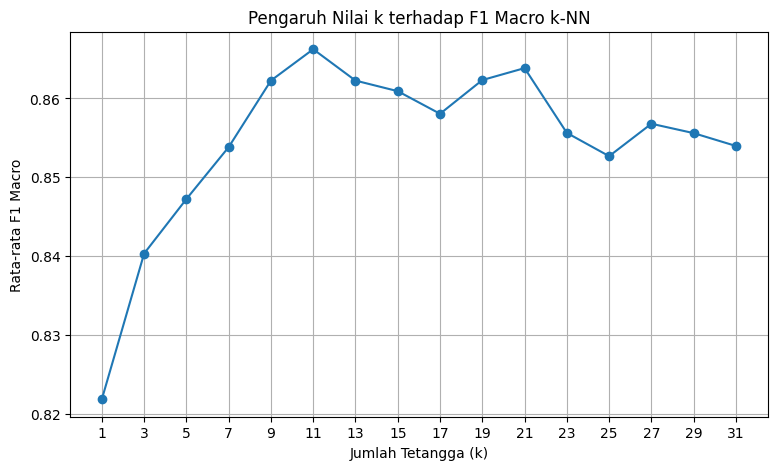

In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Mengambil hasil Grid Search
hasil_knn = pd.DataFrame(grid_knn.cv_results_)

# Memilih hasil dengan weights distance dan metric manhattan
grafik_knn = hasil_knn[
    (hasil_knn['param_model__weights'] == 'distance') &
    (hasil_knn['param_model__metric'] == 'manhattan')
].copy()

# Mengurutkan berdasarkan nilai k
grafik_knn['nilai_k'] = grafik_knn[
    'param_model__n_neighbors'
].astype(int)

grafik_knn = grafik_knn.sort_values('nilai_k')

# Membuat grafik
plt.figure(figsize=(9, 5))

plt.plot(
    grafik_knn['nilai_k'],
    grafik_knn['mean_test_score'],
    marker='o'
)

plt.title('Pengaruh Nilai k terhadap F1 Macro k-NN')
plt.xlabel('Jumlah Tetangga (k)')
plt.ylabel('Rata-rata F1 Macro')
plt.xticks(list(range(1, 32, 2)))
plt.grid(True)
plt.show()


## Langkah 4 — Melatih Naive Bayes


In [13]:

from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Pipeline Naive Bayes
pipa_nb = Pipeline(steps=[
    ('prep', buat_preprocessor(False)),
    ('model', GaussianNB())
])

# Parameter yang diuji
param_nb = {
    'model__var_smoothing': [
        1e-9,
        1e-8,
        1e-7,
        1e-6,
        1e-5
    ]
}

# Grid Search Naive Bayes
grid_nb = GridSearchCV(
    estimator=pipa_nb,
    param_grid=param_nb,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

# Melatih model
grid_nb.fit(X_train, y_train)

# Model dengan parameter terbaik
model_nb = grid_nb.best_estimator_

print('Parameter terbaik Naive Bayes:')
print(grid_nb.best_params_)

print('\nSkor F1 Macro terbaik:')
print(round(grid_nb.best_score_, 4))


Parameter terbaik Naive Bayes:
{'model__var_smoothing': 1e-09}

Skor F1 Macro terbaik:
0.8459


## Langkah 5 — Menyimpan artefak untuk Pertemuan 13


In [16]:
import joblib
import os
import sklearn

# Menghitung jumlah fitur setelah preprocessing dan encoding
preprocessor_final = buat_preprocessor(True)
X_train_final = preprocessor_final.fit_transform(X_train)

# Mengumpulkan hasil pemodelan
artefak = {
    'X_train': X_train,
    'X_test': X_test,
    'y_train': y_train,
    'y_test': y_test,
    'numerik': numerik,
    'kategorik': kategorik,
    'model_knn': model_knn,
    'model_nb': model_nb,
    'best_params_knn': grid_knn.best_params_,
    'best_params_nb': grid_nb.best_params_,
    'cv_score_knn': grid_knn.best_score_,
    'cv_score_nb': grid_nb.best_score_,
    'jumlah_fitur_encoded': X_train_final.shape[1],
    'seed': SEED,
    'sklearn_version': sklearn.__version__
}

# Menyimpan artefak ke Google Drive
PATH_ARTEFAK = os.path.join(FOLDER, 'artefak_3.joblib')

joblib.dump(artefak, PATH_ARTEFAK)

print('Artefak berhasil disimpan!')
print('Lokasi penyimpanan:', PATH_ARTEFAK)
print('Jumlah fitur setelah encoding:', X_train_final.shape[1])
print('Versi Scikit-learn:', sklearn.__version__)


Artefak berhasil disimpan!
Lokasi penyimpanan: /content/drive/MyDrive/Projek ML/artefak_3.joblib
Jumlah fitur setelah encoding: 20
Versi Scikit-learn: 1.9.1
